# ML Zoomcamp - Module 4: Evaluation Metrics for Classification (Homework 4)

Lead scoring again: predict `converted`. This module covers:
1. ROC AUC (also as a feature-importance tool)
2. Precision and recall across thresholds
3. F1 score
4. K-fold cross-validation
5. Hyperparameter tuning with CV

Run the cells top to bottom; each question prints its answer.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

## Data preparation

In [20]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
fname = "course_lead_scoring_2026.csv"

df = pd.read_csv(fname)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [21]:
print(df.shape)
print(df.isnull().sum())

(5000, 9)
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [22]:
categorical = [c for c in df.columns if c != 'converted' and df[c].dtype == 'string']
numerical = [c for c in df.columns if c != 'converted' and c not in categorical]

print("Categorical:", categorical)
print("Numerical:  ", numerical)

Categorical: ['lead_source', 'industry', 'employment_status', 'location']
Numerical:   ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


In [23]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

df.isnull().sum().sum()

np.int64(0)

## Split

In [24]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

del df_train['converted']
del df_val['converted']
del df_test['converted']

print(len(df_train), len(df_val), len(df_test))

3000 1000 1000


## Question 1: ROC AUC as feature importance

In [25]:
options = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']

rows = []
for c in options:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    rows.append({'feature': c, 'auc': auc})

roc_auc = pd.DataFrame(rows).sort_values('auc', ascending=False)
display(roc_auc)

,feature,auc
0,lead_score,0.788225
2,interaction_count,0.764920
1,number_of_courses_viewed,0.722989
3,annual_income,0.608198


## Question 2: Training the model

In [26]:
features = categorical + numerical

def make_dicts(d):
    return d[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(make_dicts(df_train))
X_val = dv.transform(make_dicts(df_val))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
auc_val = roc_auc_score(y_val, y_pred)
print("Validation AUC:", auc_val)

Validation AUC: 0.7318222288173319


## Question 3: Precision and recall

Thresholds 0.0 to 1.0, step 0.01. Computed from the confusion matrix by hand
(avoids sklearn warnings when there are no predicted positives).

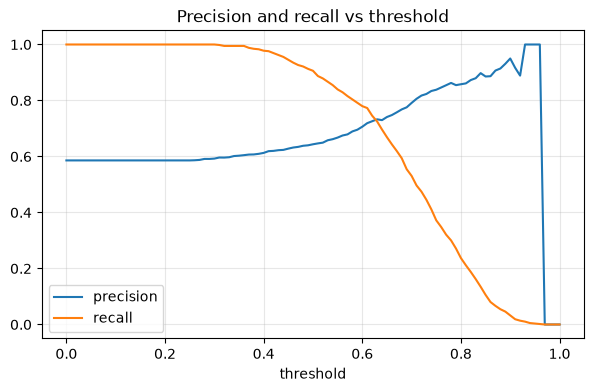

In [27]:
thresholds = np.round(np.arange(0.0, 1.01, 0.01), 2)

rows = []
for t in thresholds:
    pred = y_pred >= t
    
    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    fn = ((pred == 0) & (y_val == 1)).sum()
    tn = ((pred == 0) & (y_val == 0)).sum()
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    
    rows.append({'threshold': t, 'precision': p, 'recall': r, 'f1': f1})

scores = pd.DataFrame(rows)

plt.figure(figsize=(7, 4))
plt.plot(scores.threshold, scores.precision, label='precision')
plt.plot(scores.threshold, scores.recall, label='recall')
plt.xlabel('threshold'); plt.legend(); plt.grid(alpha=.3)
plt.title('Precision and recall vs threshold')
plt.show()

In [28]:
valid = scores[(scores.precision > 0) | (scores.recall > 0)].copy()   # ignore both-zero thresholds
valid['abs_diff'] = (valid.precision - valid.recall).abs()
best = valid.sort_values('abs_diff').iloc[0]
display(valid.sort_values('abs_diff').head(5))
print(best['threshold'])

,threshold,precision,recall,f1,abs_diff
63,0.63,0.732759,0.725256,0.728988,0.007503
62,0.62,0.725914,0.745734,0.735690,0.019820
64,0.64,0.729875,0.696246,0.712664,0.033629
61,0.61,0.719048,0.773038,0.745066,0.053990
65,0.65,0.741021,0.668942,0.703139,0.072079


0.63


## Question 4: F1 score

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032
45,0.45,0.628118,0.945392,0.754768
44,0.44,0.623608,0.955631,0.754717


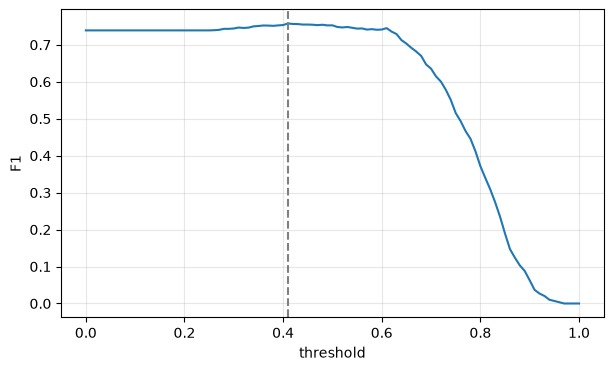

In [29]:
best_f1 = scores.loc[scores.f1.idxmax()]
display(scores.sort_values('f1', ascending=False).head(5))

plt.figure(figsize=(7, 4))
plt.plot(scores.threshold, scores.f1)
plt.axvline(best_f1['threshold'], ls='--', c='gray')
plt.xlabel('threshold'); plt.ylabel('F1'); plt.grid(alpha=.3)
plt.show()

## Question 5: 5-fold cross-validation


In [30]:
def train_fold(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_tr[features].to_dict(orient='records'))
    m = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    m.fit(X, y_tr)
    return dv, m

def predict_fold(df_v, dv, m):
    X = dv.transform(df_v[features].to_dict(orient='records'))
    return m.predict_proba(X)[:, 1]

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

aucs = []
for tr_idx, v_idx in kfold.split(df_full_train):
    d_tr = df_full_train.iloc[tr_idx]
    d_v = df_full_train.iloc[v_idx]
    dv_, m_ = train_fold(d_tr, d_tr['converted'].values)
    p = predict_fold(d_v, dv_, m_)
    aucs.append(roc_auc_score(d_v['converted'].values, p))

print("Fold AUCs:", np.round(aucs, 4))
print("Mean:", np.mean(aucs))
print("Std (ddof=0):", np.std(aucs))

Fold AUCs: [0.7306 0.7296 0.7363 0.7412 0.7209]
Mean: 0.7317269710972524
Std (ddof=0): 0.006853233151022138


## Question 6: Tune `C` with 5-fold CV

Mean and std rounded to 3 decimals. Ties: lowest std, then smallest `C`.

In [31]:
results = []
for C in [0.000001, 0.001, 1]:
    fold_aucs = []
    for tr_idx, v_idx in kfold.split(df_full_train):
        d_tr = df_full_train.iloc[tr_idx]
        d_v = df_full_train.iloc[v_idx]
        dv_, m_ = train_fold(d_tr, d_tr['converted'].values, C=C)
        p = predict_fold(d_v, dv_, m_)
        fold_aucs.append(roc_auc_score(d_v['converted'].values, p))
    results.append({'C': C, 'mean': round(np.mean(fold_aucs), 3), 'std': round(np.std(fold_aucs), 3)})

res = pd.DataFrame(results)
display(res)

best = res.sort_values(['mean', 'std', 'C'], ascending=[False, True, True]).iloc[0]

,C,mean,std
0,0.000001,0.617,0.019
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007
